In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
monthly = pd.read_csv(
    "pharma_sales_monthly_cleaned.csv"
)

monthly["sales_date"] = pd.to_datetime(
    monthly["sales_date"]
)

monthly = monthly.sort_values("sales_date")

In [6]:
#forecasting total sales volume across all eight drug categories.
forecast_df = monthly[
    ["sales_date", "total_sales_volume"]
].copy()

forecast_df = forecast_df.set_index("sales_date")

display(forecast_df.head())

,total_sales_volume
sales_date,
2014-01-31,1821.110
2014-02-28,1974.470
2014-03-31,1606.720
2014-04-30,1429.675
2014-05-31,1506.303


In [7]:
#Confirming that the data has one observation per month and no unexplained gaps.
print("Start date:", forecast_df.index.min())
print("End date:", forecast_df.index.max())
print("Number of months:", len(forecast_df))

Start date: 2014-01-31 00:00:00
End date: 2019-10-31 00:00:00
Number of months: 70


In [9]:
#reserving the last six months for testing model.
test_size = 12

train = forecast_df.iloc[:-test_size]
test = forecast_df.iloc[-test_size:]

print("Training records:", len(train))
print("Testing records:", len(test))

Training records: 58
Testing records: 12


In [12]:
#This model predicts that the next month's sales will equal the most recently observed month's sales.
naive_forecast = pd.Series(
    [train["total_sales_volume"].iloc[-1]] * len(test),
    index=test.index,
    name="naive_forecast"
)
print(naive_forecast)

sales_date
2018-11-30    2221.335
2018-12-31    2221.335
2019-01-31    2221.335
2019-02-28    2221.335
2019-03-31    2221.335
2019-04-30    2221.335
2019-05-31    2221.335
2019-06-30    2221.335
2019-07-31    2221.335
2019-08-31    2221.335
2019-09-30    2221.335
2019-10-31    2221.335
Name: naive_forecast, dtype: float64


In [13]:
#This model predicts that each month will have the same sales volume as the corresponding month one year earlier.
seasonal_forecast = pd.Series(
    [
        train["total_sales_volume"].iloc[-12 + i]
        for i in range(len(test))
    ],
    index=test.index,
    name="seasonal_forecast"
)
print(seasonal_forecast)

sales_date
2018-11-30    1705.579
2018-12-31    1887.103
2019-01-31    1985.701
2019-02-28    2203.248
2019-03-31    2156.847
2019-04-30    1934.480
2019-05-31    1675.130
2019-06-30    1414.349
2019-07-31    1563.479
2019-08-31    1611.907
2019-09-30    1981.374
2019-10-31    2221.335
Name: seasonal_forecast, dtype: float64


In [14]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

#Using MAE and RMSE to measure forecasting errors.
#MAE: Average absolute difference between actual and predicted sales volume.
#RMSE: Gives more weight to larger forecasting errors.

results = pd.DataFrame({
    "model": ["Naive", "Seasonal Naive"],
    "MAE": [
        mean_absolute_error(
            test["total_sales_volume"], naive_forecast
        ),
        mean_absolute_error(
            test["total_sales_volume"], seasonal_forecast
        )
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(
            test["total_sales_volume"], naive_forecast
        )),
        np.sqrt(mean_squared_error(
            test["total_sales_volume"], seasonal_forecast
        ))
    ]
})

display(results)

,model,MAE,RMSE
0,Naive,550.348833,690.185891
1,Seasonal Naive,372.066833,587.061060


In [15]:
future_dates = pd.date_range(
    start=forecast_df.index[-1] + pd.offsets.MonthBegin(1),
    periods=3,
    freq="MS"
)

future_forecast = pd.Series(
    [
        forecast_df["total_sales_volume"].iloc[-12 + i]
        for i in range(3)
    ],
    index=future_dates,
    name="forecast_sales_volume"
)

display(future_forecast)

2019-11-01    2008.677
2019-12-01    2277.534
2020-01-01    2907.863
Freq: MS, Name: forecast_sales_volume, dtype: float64

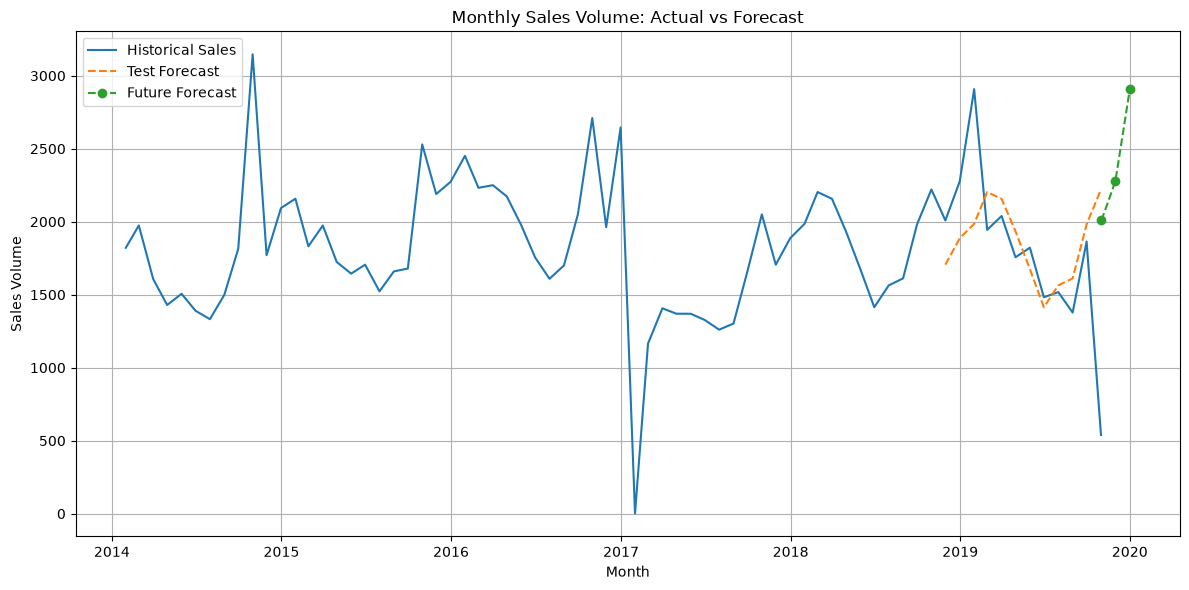

In [18]:
plt.figure(figsize=(12, 6))

plt.plot(
    forecast_df.index,
    forecast_df["total_sales_volume"],
    label="Historical Sales"
)

plt.plot(
    test.index,
    seasonal_forecast,
    label="Test Forecast",
    linestyle="--"
)

plt.plot(
    future_forecast.index,
    future_forecast,
    label="Future Forecast",
    linestyle="--",
    marker="o"
)

plt.title("Monthly Sales Volume: Actual vs Forecast")
plt.xlabel("Month")
plt.ylabel("Sales Volume")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [20]:
test_results = pd.DataFrame({
    "sales_date": test.index,
    "actual_sales_volume": test["total_sales_volume"].values,
    "forecast_sales_volume": seasonal_forecast.values,
    "forecast_type": "Test"
})

future_results = pd.DataFrame({
    "sales_date": future_forecast.index,
    "actual_sales_volume": np.nan,
    "forecast_sales_volume": future_forecast.values,
    "forecast_type": "Future"
})

forecast_results = pd.concat(
    [test_results, future_results],
    ignore_index=True
)

forecast_results.to_csv(
    r"D:\New folder\PHARMA SALES ANALYSIS\Dataset\Cleaned\forecast_results.csv",
    index=False
)